# Visualize Token Graphs Across Dynamical Complexity

This Visualize notebook loads the cache produced by `Generate-token-graphs-across-dynamical-complexity.ipynb` and generates the final-layer attention-induced token-graph figure for **Attention-Induced Token-Graph Organization Across Dynamical Complexity and Context Length** in the Results, together with the early- and middle-layer figures for **Attention-Induced Token-Graph Visualizations at Additional Transformer Layers** in the appendix.

Each $2 \times 5$ figure shows one selected Llama-3.2-3B layer across all ten input families at $N = 500$. Node positions use attention-weighted Fruchterman–Reingold layouts; edge thickness and opacity encode attention weight, and only edges above $2.5/N$ are displayed. Node colors encode the leading three uncentered hidden-state SVD coordinates. Circles mark numeric tokens and triangles mark separator tokens.


Set imports, retained inputs, and figure styles.


In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D

# Analysis window
REFERENCE_CONTEXT_TOKENS = 1000
ANALYSIS_CONTEXT_TOKENS = 500
CONTEXT_FRAC = ANALYSIS_CONTEXT_TOKENS / REFERENCE_CONTEXT_TOKENS  # Relative to the 1,000-token reference length
CONTEXT_DISPLAY_LABEL = f'{ANALYSIS_CONTEXT_TOKENS} tokens'
PROCESSED_DATA_DIR = Path('processed_graph_data')
FIGURE_OUTPUT_DIR = Path('figure')

# Attention-graph style
RGB_GRAPH_EDGE_BASE_GRAY = 0.15
RGB_GRAPH_EDGE_ALPHA_MIN = 0.06
RGB_GRAPH_EDGE_ALPHA_SPAN = 0.52
RGB_GRAPH_EDGE_ALPHA_GAMMA = 0.85
RGB_GRAPH_EDGE_LW_MIN = 0.35
RGB_GRAPH_EDGE_LW_SPAN = 1.95
RGB_GRAPH_EDGE_LW_GAMMA = 0.90
RGB_GRAPH_NODE_SIZE = 18
RGB_GRAPH_DELIMITER_SIZE = 24
RGB_GRAPH_NODE_SIZE_FLOOR = 8
RGB_GRAPH_DELIMITER_SIZE_FLOOR = 10
RGB_GRAPH_DRAW_TOKEN_ORDER_TRACE = False
RGB_GRAPH_DRAW_EDGE_THRESHOLD_FACTOR = 2.5
RGB_GRAPH_MAX_EDGES_DRAW = None
RGB_GRAPH_EDGE_STYLE_BINS = 20
LABEL_TOKEN_MARKERS = True
TOKEN_MARKER_LABELS_ONE_BASED = np.array([1, 100, 200, 300, 400, ANALYSIS_CONTEXT_TOKENS], dtype=int)
RGB_GRAPH_X_MARGIN = 0.04
RGB_GRAPH_Y_MARGIN = 0.10
# Layerwise 2 x 5 layout
FIGURE_SIZE = (13.3, 7.4)
DISPLAY_DPI = 150
FIGURE_DPI = 300
SUBPLOT_ADJUST = dict(left=0.005, right=0.995, bottom=0.100, top=0.930, wspace=0.0, hspace=0.06)
SAVEFIG_PAD_INCHES = 0.005
FONT_SIZE_SCALE = 1.10
PANEL_TITLE_FONT_SIZE = 14.6
PANEL_TITLE_Y_OFFSET = 0.001

plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'
plt.rcParams['figure.dpi'] = DISPLAY_DPI
plt.rcParams['font.size'] = plt.rcParamsDefault['font.size'] * FONT_SIZE_SCALE
plt.rcParams['savefig.dpi'] = FIGURE_DPI


In [2]:

# Retained input order and labels
DATA_ORDER = [
    'Constant 500',
    'Logistic r=3.2',
    'Logistic r=3.5',
    'Logistic r=3.55',
    'Logistic r=3.566',
    'Logistic r=3.5692',
    'Logistic r=3.5698',
    'Logistic r=3.9',
    'Logistic r=4.0',
    'Lorenz',
]

DATA_TITLE_OVERRIDES = {
    'Constant 500': 'Constant sequence',
    'Logistic r=3.2': 'Logistic period 2',
    'Logistic r=3.5': 'Logistic period 4',
    'Logistic r=3.55': 'Logistic period 8',
    'Logistic r=3.566': 'Logistic period 16',
    'Logistic r=3.5692': 'Logistic period 32',
    'Logistic r=3.5698': 'Logistic period 64',
}

DATA_TITLE_SUFFIXES = {
    'Logistic r=3.9': 'chaotic',
    'Logistic r=4.0': 'chaotic',
    'Lorenz': 'chaotic',
}

GRAPH_DATA_ARRAY_KEYS = (
    'layer_indices',
    'Wbar',
    'layout_positions',
    'svd_projection_coords',
    'svd_cumulative_energy_ratio',
    'is_delimiter',
)


def panel_title(data_name):
    data_name = str(data_name)
    title = DATA_TITLE_OVERRIDES.get(data_name, data_name)
    suffix = DATA_TITLE_SUFFIXES.get(data_name)
    return f'{title} ({suffix})' if suffix else title


def context_display_label(num_tokens=ANALYSIS_CONTEXT_TOKENS):
    return f'{int(num_tokens)} tokens'


def context_fraction_label(frac):
    pct = int(round(100 * float(frac)))
    return f'context{pct}'


def safe_data_stem(data_name, frac):
    name = str(data_name).replace('=', '_').replace('.', '_')
    name = re.sub(r'[^A-Za-z0-9]+', '_', name).strip('_').lower()
    return f'{name}_{context_fraction_label(frac)}'


def graph_data_path(data_name, frac=CONTEXT_FRAC, data_dir=PROCESSED_DATA_DIR):
    return Path(data_dir) / f'{safe_data_stem(data_name, frac)}_graph_data.npz'


Load and validate the processed graph archives.


In [3]:

def load_processed_graph_data(data_name, frac=CONTEXT_FRAC, data_dir=PROCESSED_DATA_DIR):
    path = graph_data_path(data_name, frac=frac, data_dir=data_dir)
    if not path.exists():
        raise FileNotFoundError(path)

    with np.load(path, allow_pickle=False) as npz:
        processed_data = {key: npz[key] for key in npz.files}

    missing = [key for key in GRAPH_DATA_ARRAY_KEYS if key not in processed_data]
    if missing:
        raise KeyError(f'{path} is missing required arrays: {missing}')
    extra = sorted(set(processed_data) - set(GRAPH_DATA_ARRAY_KEYS))
    if extra:
        raise KeyError(f'{path} contains unexpected arrays: {extra}')
    return processed_data


def check_processed_graph_data(data_names=DATA_ORDER, frac=CONTEXT_FRAC, data_dir=PROCESSED_DATA_DIR):
    missing = []
    invalid = []
    for data_name in data_names:
        path = graph_data_path(data_name, frac=frac, data_dir=data_dir)
        if not path.exists():
            missing.append(path)
            continue
        try:
            load_processed_graph_data(data_name, frac=frac, data_dir=data_dir)
        except (OSError, KeyError, ValueError) as exc:
            invalid.append((path, exc))

    if missing:
        raise FileNotFoundError('Missing processed graph data:\n' + '\n'.join(str(path) for path in missing))
    if invalid:
        details = '\n'.join(f'{path}: {exc}' for path, exc in invalid)
        raise ValueError('Invalid processed graph data:\n' + details)


Prepare and draw attention-induced token graphs.


In [4]:
def edge_weight_threshold_from_uniform(n_nodes, factor):
    n_nodes = int(n_nodes)
    if n_nodes <= 0:
        return float('inf')
    return float(factor) / float(n_nodes)



def _minmax_scale_rgb_channels(coords, fill_value=0.5, eps=1e-12):
    coords = np.asarray(coords, dtype=float)
    if coords.ndim == 1:
        coords = coords[:, None]
    if coords.ndim != 2:
        raise ValueError('coords must be 2D (num_tokens x num_components)')

    n = coords.shape[0]
    rgb = np.full((n, 3), float(fill_value), dtype=float)
    if n == 0:
        return rgb

    for k in range(3):
        if coords.shape[1] <= k:
            continue
        col = np.asarray(coords[:, k], dtype=float)
        finite = np.isfinite(col)
        if not np.any(finite):
            continue
        cmin = float(np.min(col[finite]))
        cmax = float(np.max(col[finite]))
        if (cmax - cmin) <= float(eps):
            rgb[finite, k] = float(fill_value)
        else:
            rgb[finite, k] = (col[finite] - cmin) / (cmax - cmin)

    rgb[~np.isfinite(rgb)] = float(fill_value)
    return np.clip(rgb, 0.0, 1.0)


def select_top_edges(W, max_edges=None, threshold=None, threshold_factor=RGB_GRAPH_DRAW_EDGE_THRESHOLD_FACTOR):
    W = np.asarray(W, dtype=float).copy()
    if W.ndim != 2 or W.shape[0] != W.shape[1]:
        raise ValueError('W must be square')

    n = W.shape[0]
    if n < 2:
        return np.empty((0,), dtype=int), np.empty((0,), dtype=int), np.empty((0,), dtype=float)

    W[~np.isfinite(W)] = 0.0
    np.fill_diagonal(W, 0.0)
    iu = np.triu_indices(n, k=1)
    w = W[iu]

    edge_threshold = edge_weight_threshold_from_uniform(n, threshold_factor) if threshold is None else float(threshold)
    pos_mask = np.isfinite(w) & (w > edge_threshold)
    if not np.any(pos_mask):
        return np.empty((0,), dtype=int), np.empty((0,), dtype=int), np.empty((0,), dtype=float)

    pos_idx = np.nonzero(pos_mask)[0]
    w_pos = w[pos_mask]

    if max_edges is None:
        chosen = pos_idx
    else:
        k = min(int(max_edges), w_pos.size)
        if k <= 0:
            return np.empty((0,), dtype=int), np.empty((0,), dtype=int), np.empty((0,), dtype=float)
        if k < w_pos.size:
            top_local = np.argpartition(w_pos, -k)[-k:]
            chosen = pos_idx[top_local]
        else:
            chosen = pos_idx

    order = np.argsort(w[chosen])[::-1]
    chosen = chosen[order]
    return iu[0][chosen], iu[1][chosen], w[chosen]


def token_marker_indices_and_labels(n, marker_labels_one_based=TOKEN_MARKER_LABELS_ONE_BASED):
    marker_labels = np.asarray(marker_labels_one_based, dtype=int)
    valid = (marker_labels >= 1) & (marker_labels <= int(n))
    marker_labels = marker_labels[valid]
    marker_indices = marker_labels - 1
    return marker_indices.astype(int), marker_labels.astype(int)


def annotate_token_position_markers(
    ax,
    x,
    y,
    marker_indices,
    marker_labels=None,
    label_markers=LABEL_TOKEN_MARKERS,
    label_position_overrides=None,
):
    marker_indices = np.asarray(marker_indices, dtype=int)
    if marker_labels is None:
        marker_labels = marker_indices + 1
    marker_labels = np.asarray(marker_labels, dtype=int)
    if marker_indices.size == 0:
        return

    valid = (marker_indices >= 0) & (marker_indices < len(x))
    marker_indices = marker_indices[valid]
    marker_labels = marker_labels[valid]
    if marker_indices.size == 0:
        return

    ax.scatter(
        x[marker_indices],
        y[marker_indices],
        s=70,
        facecolors='white',
        edgecolors='#111111',
        linewidths=1.35,
        alpha=0.98,
        zorder=7,
        clip_on=False,
    )

    if not label_markers:
        return

    label_position_overrides = label_position_overrides or {}
    for idx, label in zip(marker_indices, marker_labels):
        label_style = dict(xytext=(3, 3), ha='left', va='bottom')
        label_style.update(label_position_overrides.get(int(label), {}))
        ax.annotate(
            f'{int(label)}',
            (x[idx], y[idx]),
            xytext=label_style['xytext'],
            textcoords='offset points',
            fontsize=7.35 * FONT_SIZE_SCALE,
            fontweight='bold',
            ha=label_style['ha'],
            va=label_style['va'],
            color='#000000',
            bbox=dict(boxstyle='round,pad=0.14', facecolor='white', edgecolor='#111111', linewidth=0.35, alpha=0.92),
            zorder=8,
            annotation_clip=False,
            clip_on=False,
        )


def draw_processed_layer_on_ax(
    ax,
    W,
    xy,
    rgb,
    is_delimiter,
    edge_threshold_factor=RGB_GRAPH_DRAW_EDGE_THRESHOLD_FACTOR,
    max_edges=RGB_GRAPH_MAX_EDGES_DRAW,
    edge_weight_limits=None,
    label_token_markers=LABEL_TOKEN_MARKERS,
    marker_label_position_overrides=None,
):
    W = np.asarray(W, dtype=float)
    xy = np.asarray(xy, dtype=float)
    rgb = np.asarray(rgb, dtype=float)
    is_delimiter = np.asarray(is_delimiter, dtype=bool)

    n = min(W.shape[0], xy.shape[0], rgb.shape[0], is_delimiter.shape[0])
    if n == 0:
        ax.axis('off')
        return {'n': 0, 'edge_count': 0}

    W = W[:n, :n]
    xy = xy[:n]
    rgb = np.clip(rgb[:n], 0.0, 1.0)
    is_delimiter = is_delimiter[:n]
    x = xy[:, 0]
    y = xy[:, 1]

    i_idx, j_idx, w_edges = select_top_edges(
        W,
        max_edges=max_edges,
        threshold_factor=edge_threshold_factor,
    )

    if RGB_GRAPH_DRAW_TOKEN_ORDER_TRACE and n > 1:
        ax.plot(x, y, color='#BBBBBB', linewidth=0.6, alpha=0.5, zorder=1)

    if w_edges.size > 0:
        segments = np.stack([
            np.column_stack([x[i_idx], y[i_idx]]),
            np.column_stack([x[j_idx], y[j_idx]]),
        ], axis=1)

        if edge_weight_limits is None:
            w_min = float(np.min(w_edges))
            w_max = float(np.max(w_edges))
        else:
            w_min, w_max = (float(value) for value in edge_weight_limits)
        w_scaled = np.clip((w_edges - w_min) / (w_max - w_min), 0.0, 1.0) if w_max > w_min else np.ones_like(w_edges)
        n_style_bins = max(1, int(RGB_GRAPH_EDGE_STYLE_BINS))
        bin_indices = np.minimum((w_scaled * n_style_bins).astype(int), n_style_bins - 1)
        bin_centers = (np.arange(n_style_bins, dtype=float) + 0.5) / n_style_bins

        for bin_idx, bin_center in enumerate(bin_centers):
            mask = bin_indices == bin_idx
            if not np.any(mask):
                continue
            edge_alpha = RGB_GRAPH_EDGE_ALPHA_MIN + RGB_GRAPH_EDGE_ALPHA_SPAN * (bin_center ** RGB_GRAPH_EDGE_ALPHA_GAMMA)
            edge_lw = RGB_GRAPH_EDGE_LW_MIN + RGB_GRAPH_EDGE_LW_SPAN * (bin_center ** RGB_GRAPH_EDGE_LW_GAMMA)
            edge_rgba = (RGB_GRAPH_EDGE_BASE_GRAY, RGB_GRAPH_EDGE_BASE_GRAY, RGB_GRAPH_EDGE_BASE_GRAY, edge_alpha)
            ax.add_collection(LineCollection(segments[mask], colors=[edge_rgba], linewidths=edge_lw, zorder=2))

    state_mask = ~is_delimiter
    if np.any(state_mask):
        ax.scatter(
            x[state_mask],
            y[state_mask],
            c=rgb[state_mask],
            s=max(float(RGB_GRAPH_NODE_SIZE_FLOOR), RGB_GRAPH_NODE_SIZE * 0.8),
            alpha=0.95,
            marker='o',
            edgecolors='none',
            zorder=3,
        )

    if np.any(is_delimiter):
        ax.scatter(
            x[is_delimiter],
            y[is_delimiter],
            c=rgb[is_delimiter],
            s=max(float(RGB_GRAPH_DELIMITER_SIZE_FLOOR), RGB_GRAPH_DELIMITER_SIZE * 0.8),
            alpha=0.95,
            marker='^',
            edgecolors='none',
            zorder=4,
        )

    if label_token_markers:
        marker_indices, marker_labels = token_marker_indices_and_labels(n)
        annotate_token_position_markers(
            ax,
            x,
            y,
            marker_indices,
            marker_labels=marker_labels,
            label_markers=label_token_markers,
            label_position_overrides=marker_label_position_overrides,
        )

    ax.set_aspect('equal', adjustable='box')
    ax.axis('off')
    ax.margins(x=RGB_GRAPH_X_MARGIN, y=RGB_GRAPH_Y_MARGIN)
    return {'n': int(n), 'edge_count': int(w_edges.size)}


In [5]:
def layer_offset(processed_data, layer_index):
    layer_indices = np.asarray(processed_data['layer_indices'], dtype=int)
    matches = np.nonzero(layer_indices == int(layer_index))[0]
    if matches.size == 0:
        available = ', '.join(str(int(layer)) for layer in layer_indices) if layer_indices.size else 'none'
        raise ValueError(f'Layer {layer_index} is unavailable. Available one-based layers: {available}')
    return int(matches[0])


def available_layer_indices(data_name=DATA_ORDER[0], frac=CONTEXT_FRAC, data_dir=PROCESSED_DATA_DIR):
    processed_data = load_processed_graph_data(data_name, frac=frac, data_dir=data_dir)
    return np.asarray(processed_data['layer_indices'], dtype=int)


def add_row_aligned_panel_titles(fig, axes, titles, ncols=5):
    fig.canvas.draw()
    for row_start in range(0, len(titles), ncols):
        row_axes = axes[row_start:row_start + ncols]
        row_titles = titles[row_start:row_start + ncols]
        title_y = row_axes[0].get_position().y1 + PANEL_TITLE_Y_OFFSET
        for ax, title in zip(row_axes, row_titles):
            pos = ax.get_position()
            fig.text(
                pos.x0 + 0.5 * pos.width,
                title_y,
                title,
                ha='center',
                va='bottom',
                fontsize=PANEL_TITLE_FONT_SIZE,
            )


Assemble the selected-layer graph figures.


In [6]:
def collect_layer_panel_data_for_global_edge_norm(
    layer_index,
    frac=CONTEXT_FRAC,
    data_names=DATA_ORDER,
    data_dir=PROCESSED_DATA_DIR,
    edge_threshold_factor=RGB_GRAPH_DRAW_EDGE_THRESHOLD_FACTOR,
):
    layer_index = int(layer_index)
    panel_data = []
    all_edge_weights = []

    for data_name in data_names:
        processed_data = load_processed_graph_data(data_name, frac=frac, data_dir=data_dir)
        layer_indices = np.asarray(processed_data['layer_indices'], dtype=int)
        offset = layer_offset(processed_data, layer_index)

        Wbar = np.asarray(processed_data['Wbar'], dtype=np.float32)[offset]
        layout_positions = np.asarray(processed_data['layout_positions'], dtype=np.float32)[offset]
        svd_projection_coords = np.asarray(processed_data['svd_projection_coords'], dtype=np.float32)[offset]
        rgb_colors = _minmax_scale_rgb_channels(svd_projection_coords).astype(np.float32)
        is_delimiter = np.asarray(processed_data['is_delimiter'], dtype=bool)

        _, _, w_edges = select_top_edges(
            Wbar,
            max_edges=RGB_GRAPH_MAX_EDGES_DRAW,
            threshold_factor=edge_threshold_factor,
        )
        if w_edges.size:
            all_edge_weights.append(w_edges)

        panel_data.append(
            dict(
                data_name=data_name,
                last_layer_index=int(layer_indices[-1]),
                Wbar=Wbar,
                layout_positions=layout_positions,
                rgb_colors=rgb_colors,
                is_delimiter=is_delimiter,
            )
        )

    if all_edge_weights:
        all_edge_weights = np.concatenate(all_edge_weights)
        edge_weight_limits = (float(np.min(all_edge_weights)), float(np.max(all_edge_weights)))
    else:
        edge_weight_limits = (0.0, 0.0)

    return panel_data, edge_weight_limits


def add_layerwise_graph_figure_key(fig):
    marker_handles = [
        Line2D(
            [0], [0], marker='o', linestyle='None', markerfacecolor='#777777',
            markeredgecolor='none', markersize=7.2
        ),
        Line2D(
            [0], [0], marker='^', linestyle='None', markerfacecolor='#777777',
            markeredgecolor='none', markersize=7.8
        ),
        Line2D(
            [0], [0], marker='o', linestyle='None', markerfacecolor='white',
            markeredgecolor='#111111', markeredgewidth=1.3, markersize=8.3
        ),
        Line2D(
            [0, 1], [0, 0], color='#444444', linewidth=2.5, alpha=0.80
        ),
        Line2D(
            [0], [0], marker='o', linestyle='None', markerfacecolor='#7B6FC8',
            markeredgecolor='none', markersize=7.8
        ),
    ]
    marker_labels = [
        'Numeric-token nodes',
        'Separator-token nodes',
        'Input position markers',
        ' Attention-weighted edges',
        'Token hidden-state signal',
    ]
    fig.legend(
        handles=marker_handles,
        labels=marker_labels,
        loc='lower center',
        bbox_to_anchor=(0.5, 0.070),
        ncol=5,
        frameon=True,
        fontsize=13.1,
        handlelength=1.05,
        handletextpad=0.08,
        columnspacing=0.25,
        borderaxespad=0.0,
    )


def plot_layer_across_inputs_global_edge_norm(
    layer_index,
    frac=CONTEXT_FRAC,
    data_names=DATA_ORDER,
    data_dir=PROCESSED_DATA_DIR,
    figure_output_dir=FIGURE_OUTPUT_DIR,
    save=False,
    save_filename='last_layer_graph.pdf',
    show=True,
    label_token_markers=LABEL_TOKEN_MARKERS,
    edge_threshold_factor=RGB_GRAPH_DRAW_EDGE_THRESHOLD_FACTOR,
):
    layer_index = int(layer_index)
    if layer_index < 1:
        raise ValueError('Use one-based layer indices.')

    panel_data, edge_weight_limits = collect_layer_panel_data_for_global_edge_norm(
        layer_index=layer_index,
        frac=frac,
        data_names=data_names,
        data_dir=data_dir,
        edge_threshold_factor=edge_threshold_factor,
    )

    fig, axes = plt.subplots(2, 5, figsize=FIGURE_SIZE, dpi=DISPLAY_DPI)
    axes = np.asarray(axes).ravel()
    panel_titles = [panel_title(payload['data_name']) for payload in panel_data]

    for ax, payload in zip(axes, panel_data):
        marker_label_position_overrides = None
        if layer_index == payload['last_layer_index'] and payload['data_name'] == 'Logistic r=3.5698':
            marker_label_position_overrides = {1: dict(xytext=(3, -3), ha='left', va='top')}
        draw_processed_layer_on_ax(
            ax,
            payload['Wbar'],
            payload['layout_positions'],
            payload['rgb_colors'],
            payload['is_delimiter'],
            edge_weight_limits=edge_weight_limits,
            label_token_markers=label_token_markers,
            edge_threshold_factor=edge_threshold_factor,
            marker_label_position_overrides=marker_label_position_overrides,
        )

    for ax in axes[len(panel_data):]:
        ax.axis('off')

    fig.subplots_adjust(**SUBPLOT_ADJUST)
    add_row_aligned_panel_titles(fig, axes, panel_titles, ncols=5)
    add_layerwise_graph_figure_key(fig)

    if save:
        figure_output_dir = Path(figure_output_dir)
        figure_output_dir.mkdir(parents=True, exist_ok=True)
        fig.savefig(figure_output_dir / str(save_filename), bbox_inches='tight', pad_inches=SAVEFIG_PAD_INCHES, dpi=FIGURE_DPI)

    if show:
        plt.show()

    return fig


Validate the cache and render the final-layer figure.


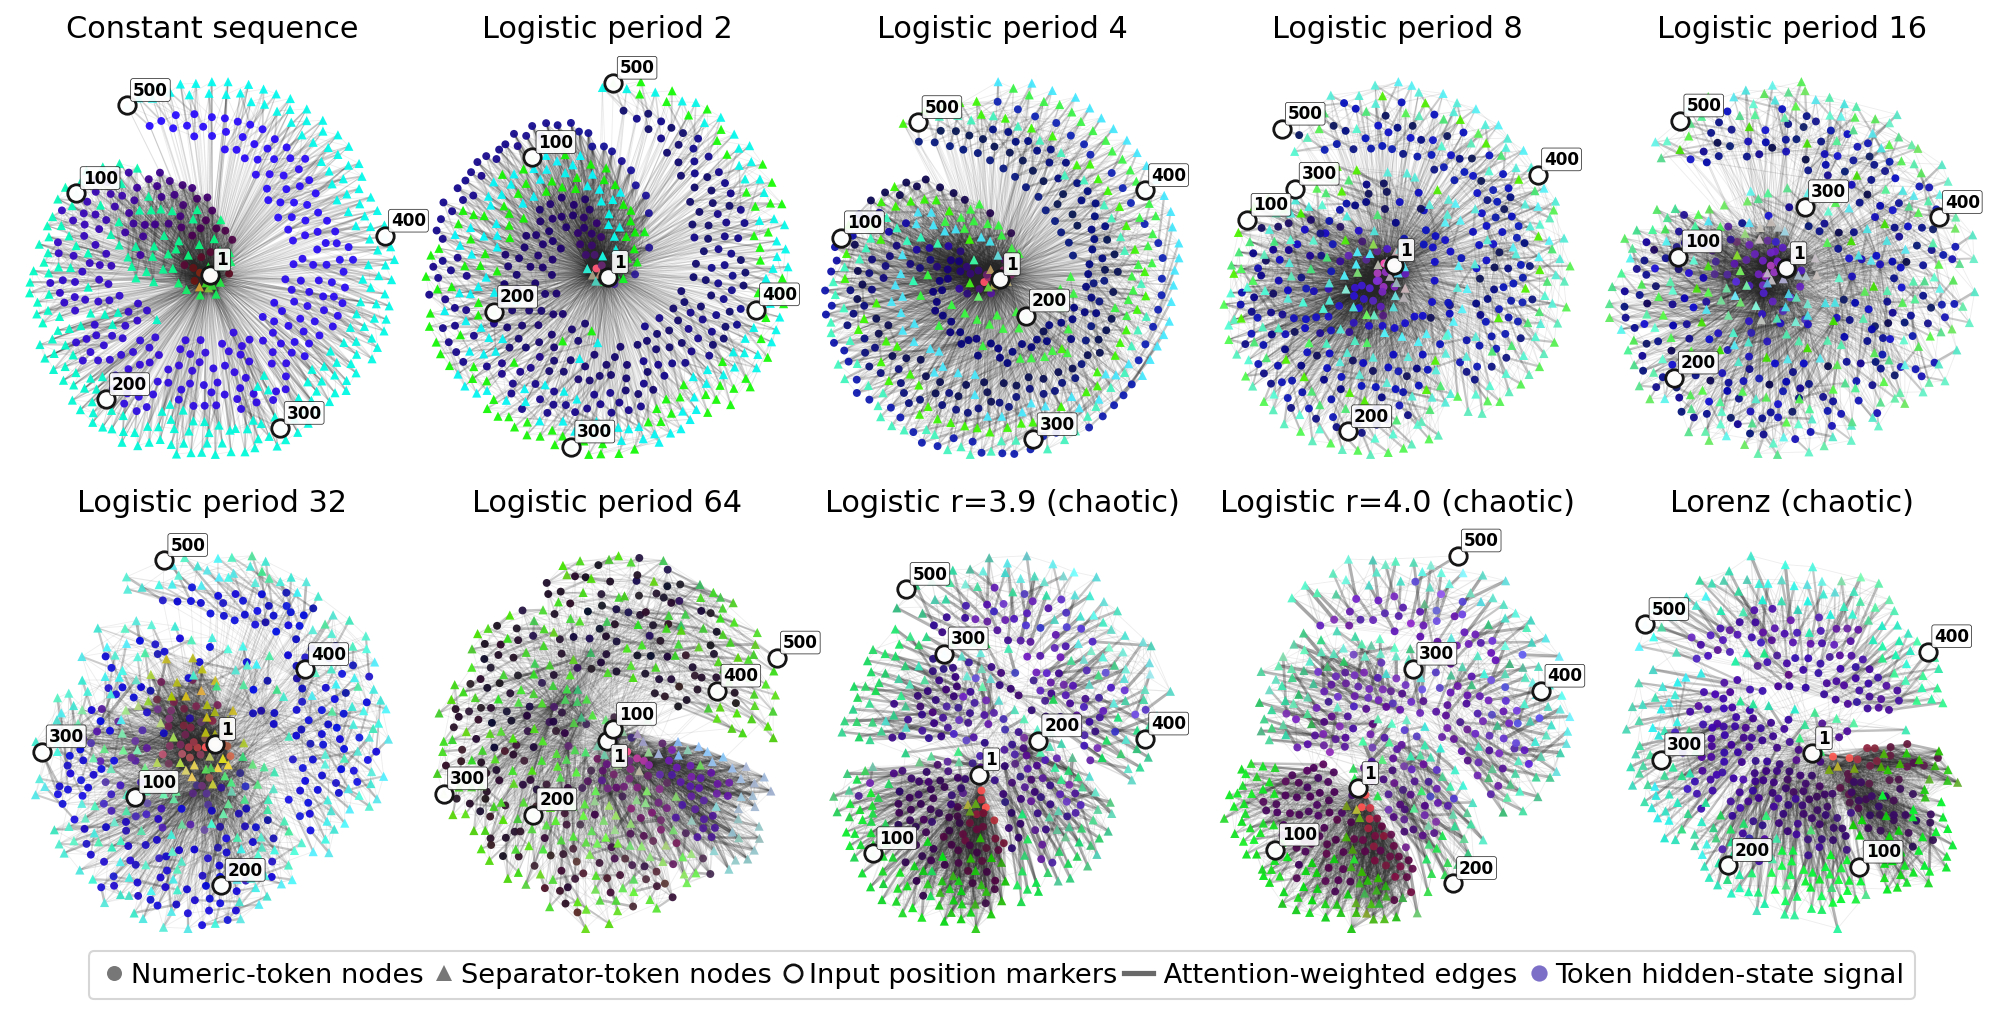

In [7]:
check_processed_graph_data()
LAYER_INDEX = int(available_layer_indices()[-1])

plot_layer_across_inputs_global_edge_norm(
    layer_index=LAYER_INDEX,
    frac=CONTEXT_FRAC,
    save=True,
    show=True,
);


Render the early- and middle-layer appendix figures.


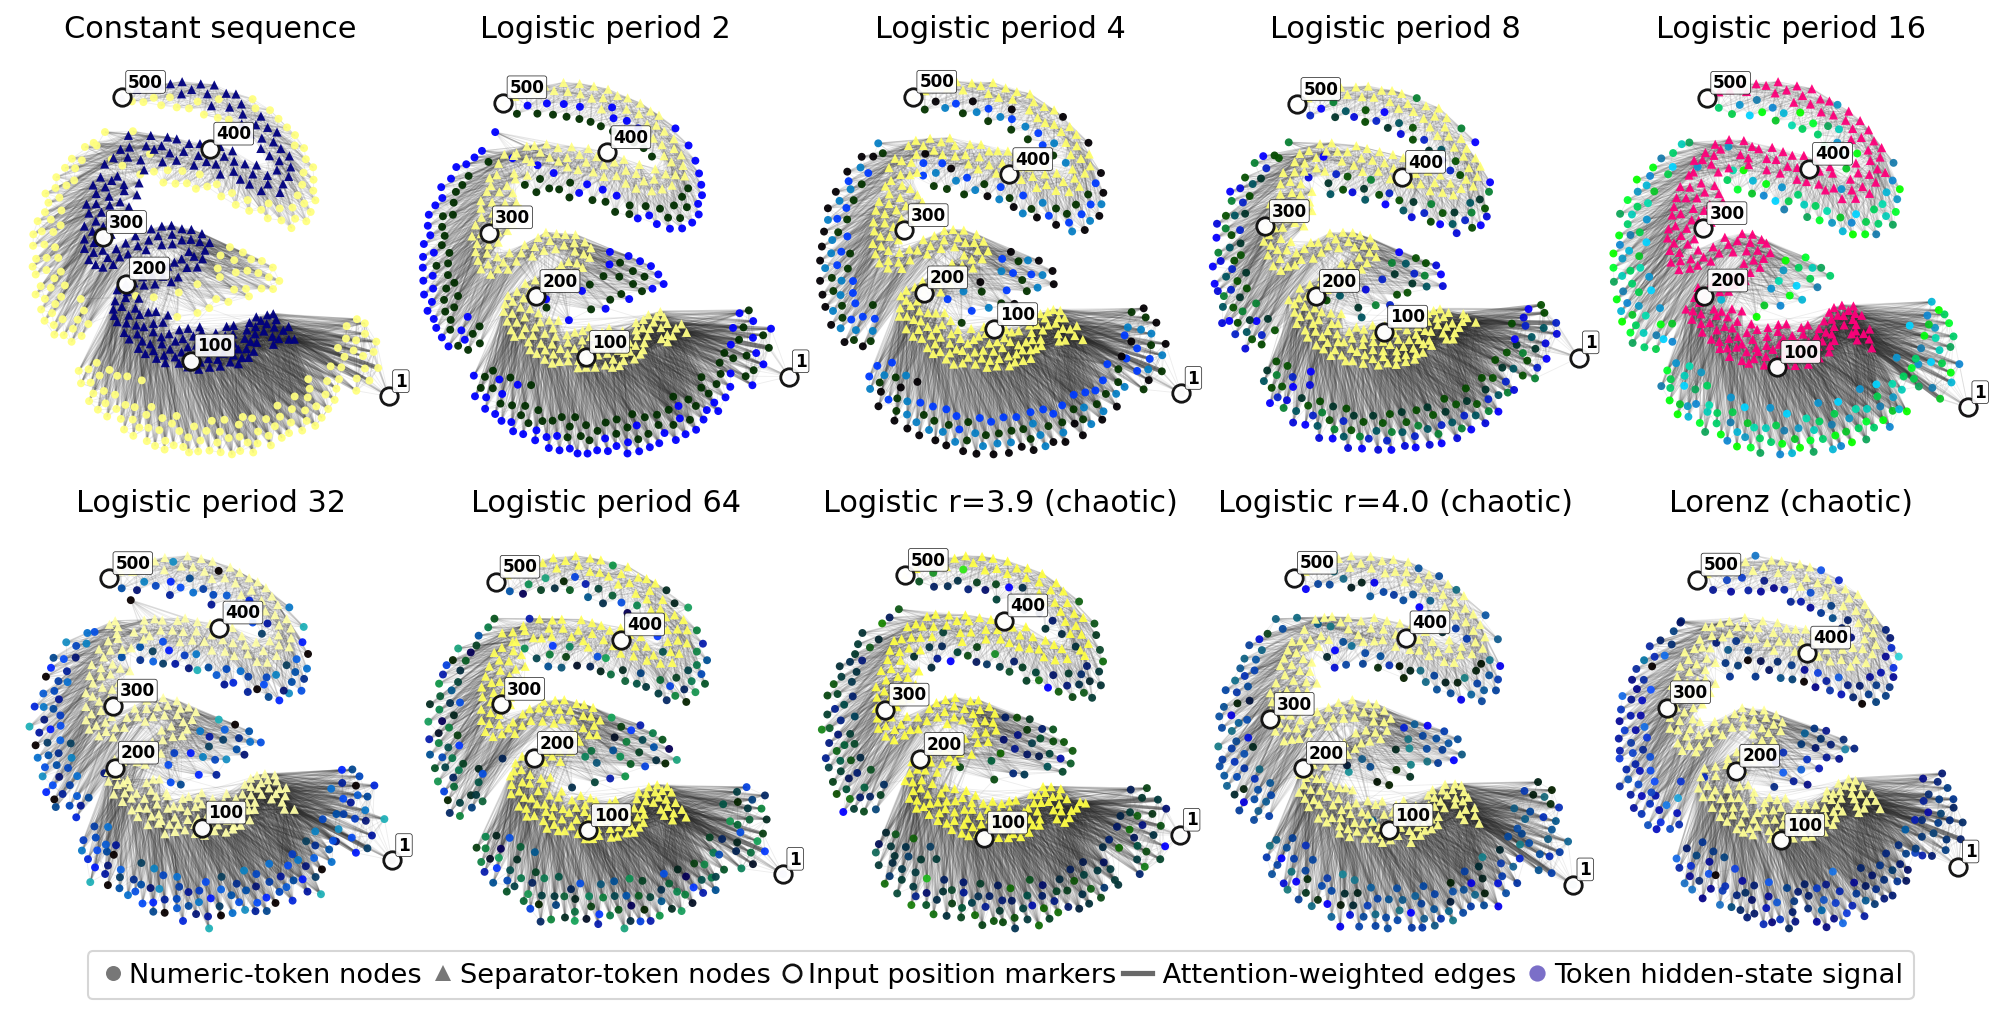

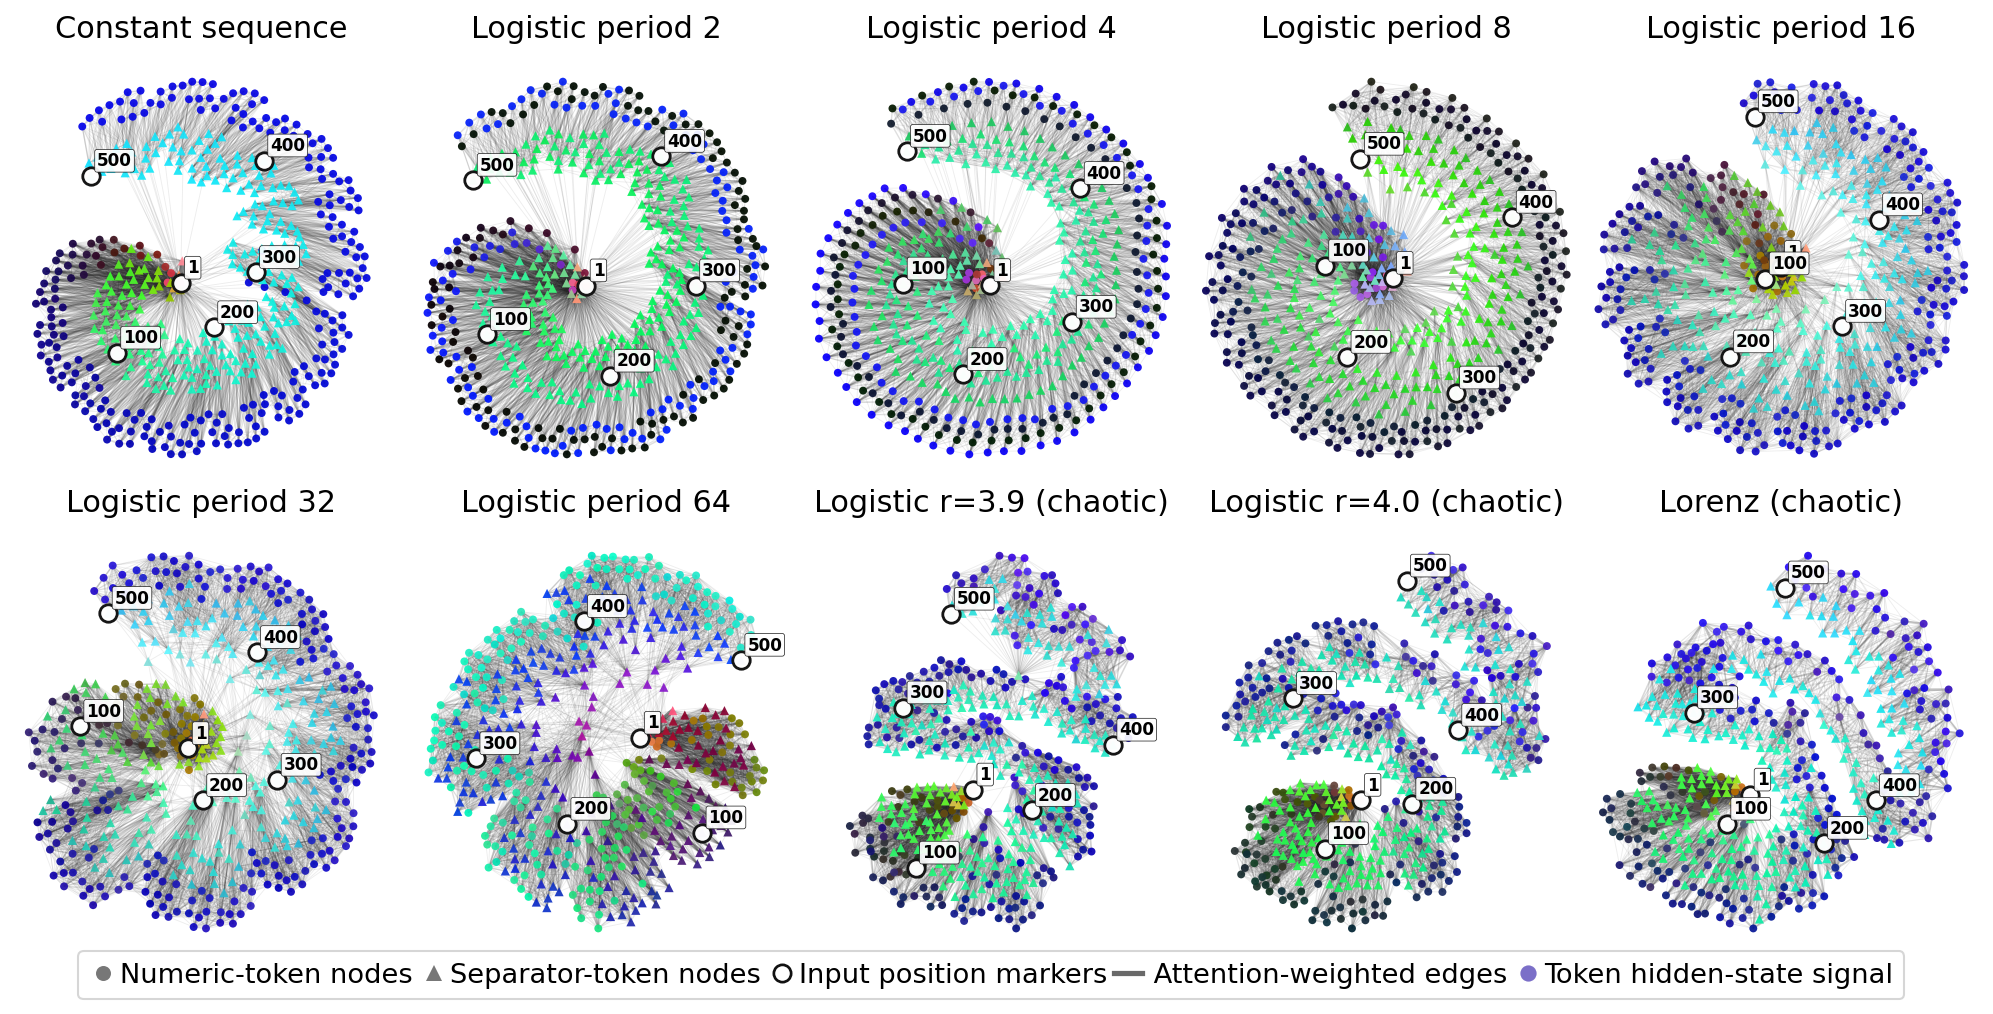

In [8]:
check_processed_graph_data()

plot_layer_across_inputs_global_edge_norm(
    layer_index=1,
    frac=CONTEXT_FRAC,
    save=True,
    save_filename="layer_1_graph.pdf",
    show=True,
);

plot_layer_across_inputs_global_edge_norm(
    layer_index=12,
    frac=CONTEXT_FRAC,
    save=True,
    save_filename="layer_12_graph.pdf",
    show=True,
);
